In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("bank_marketing_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (41176, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [2]:
# Check dataset information
df.info()

# Check statistical summary. count, mean, standard deviation, minimum, maximum, and quartiles for numerical columns.
df.describe()

# Check column names
print("Column names:")
print(df.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41176 entries, 0 to 41175
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41176 non-null  int64  
 1   job             41176 non-null  object 
 2   marital         41176 non-null  object 
 3   education       41176 non-null  object 
 4   default         41176 non-null  object 
 5   housing         41176 non-null  object 
 6   loan            41176 non-null  object 
 7   contact         41176 non-null  object 
 8   month           41176 non-null  object 
 9   day_of_week     41176 non-null  object 
 10  duration        41176 non-null  int64  
 11  campaign        41176 non-null  int64  
 12  pdays           41176 non-null  int64  
 13  previous        41176 non-null  int64  
 14  poutcome        41176 non-null  object 
 15  emp.var.rate    41176 non-null  float64
 16  cons.price.idx  41176 non-null  float64
 17  cons.conf.idx   41176 non-null 

In [3]:
# Select important numerical columns
columns = ["age", "duration", "campaign", "previous"]

# Calculate mean, median, and standard deviation
for col in columns:
    print(f"\nColumn: {col}")
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Standard Deviation:", df[col].std())


Column: age
Mean: 40.02380027200311
Median: 38.0
Standard Deviation: 10.420679868942797

Column: duration
Mean: 258.3158150378861
Median: 180.0
Standard Deviation: 259.3053209542693

Column: campaign
Mean: 2.567879347192539
Median: 2.0
Standard Deviation: 2.7703183363788746

Column: previous
Mean: 0.17301340586749564
Median: 0.0
Standard Deviation: 0.49496438138179033


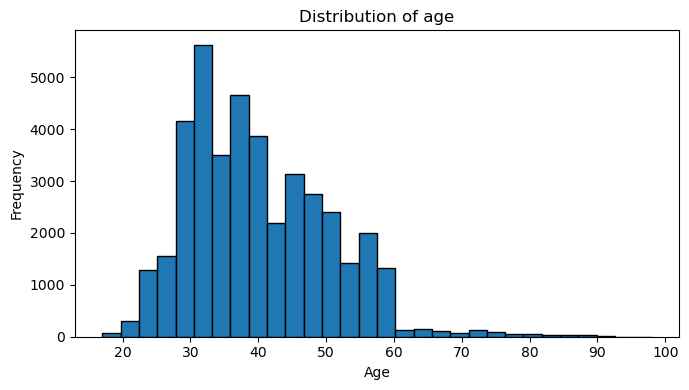

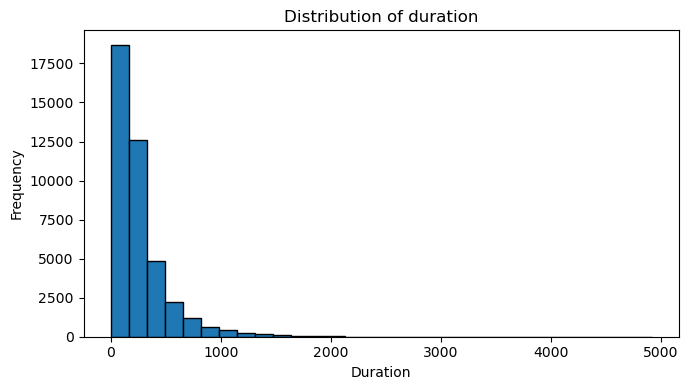

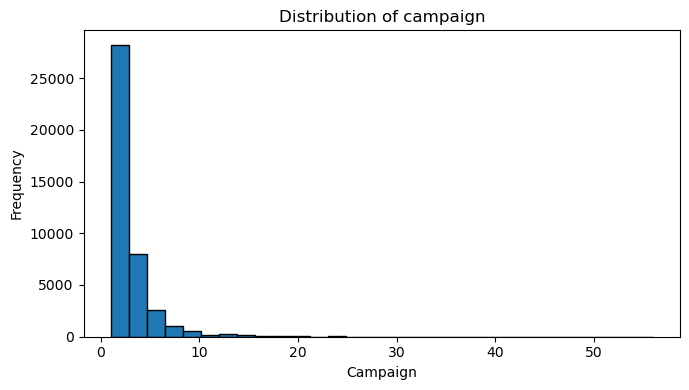

In [4]:
# Plot histograms for numerical columns

columns = ["age", "duration", "campaign"]

for col in columns:
    plt.figure(figsize=(7, 4))
    plt.hist(df[col], bins=30, edgecolor="black")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col.capitalize())
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

Job distribution:
job
admin.           10419
blue-collar       9253
technician        6739
services          3967
management        2924
retired           1718
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

Target variable distribution:
y
no     36537
yes     4639
Name: count, dtype: int64


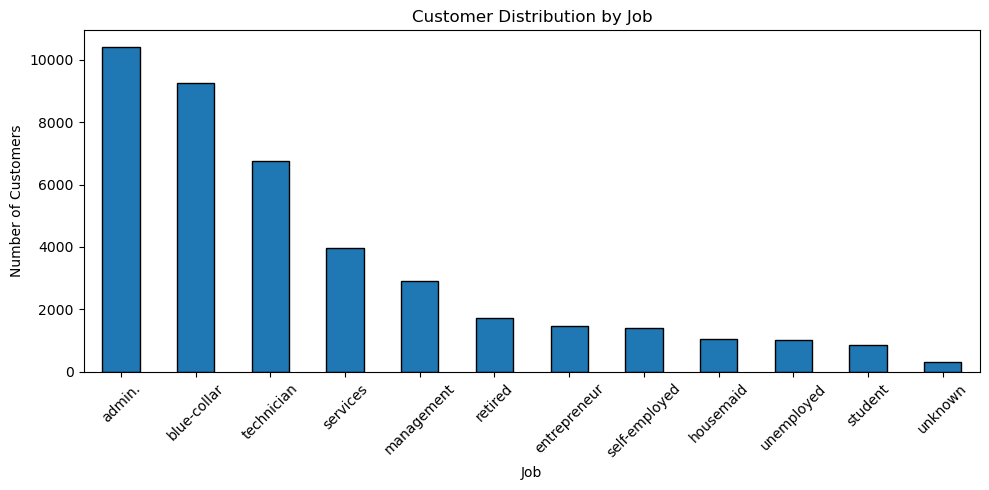

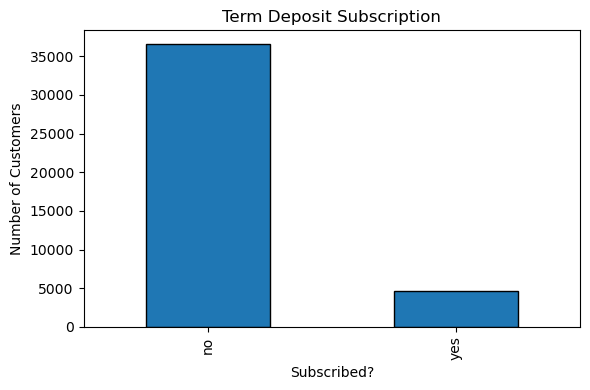

In [5]:
# Analyze categorical columns
print("Job distribution:")
print(df["job"].value_counts())

print("\nTarget variable distribution:")
print(df["y"].value_counts())

# Visualize job distribution
df["job"].value_counts().plot(
    kind="bar",
    figsize=(10, 5),
    edgecolor="black"
)

plt.title("Customer Distribution by Job")
plt.xlabel("Job")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Visualize target variable
df["y"].value_counts().plot(
    kind="bar",
    figsize=(6, 4),
    edgecolor="black"
)

plt.title("Term Deposit Subscription")
plt.xlabel("Subscribed?")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

               age  duration  campaign  previous
age       1.000000 -0.000808  0.004622  0.024379
duration -0.000808  1.000000 -0.071765  0.020600
campaign  0.004622 -0.071765  1.000000 -0.079182
previous  0.024379  0.020600 -0.079182  1.000000


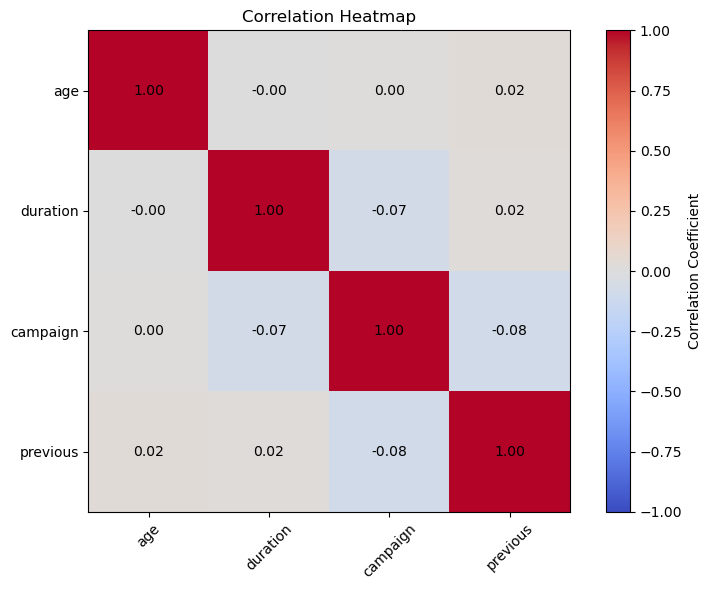

In [6]:
# Select numerical columns
numerical_df = df[
    ["age", "duration", "campaign", "previous"]
]

# Calculate Pearson correlation
correlation_matrix = numerical_df.corr()

print(correlation_matrix)

# Visualize correlation using a heatmap
plt.figure(figsize=(8, 6))

plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation Coefficient")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [7]:
# Compare average values for subscription outcomes

print("Average age by subscription:")
print(df.groupby("y")["age"].mean())

print("\nAverage call duration by subscription:")
print(df.groupby("y")["duration"].mean())

print("\nAverage campaign contacts by subscription:")
print(df.groupby("y")["campaign"].mean())

Average age by subscription:
y
no     39.910994
yes    40.912266
Name: age, dtype: float64

Average call duration by subscription:
y
no     220.868079
yes    553.256090
Name: duration, dtype: float64

Average campaign contacts by subscription:
y
no     2.633385
yes    2.051951
Name: campaign, dtype: float64


y                 no    yes
job                        
admin.         87.03  12.97
blue-collar    93.10   6.90
entrepreneur   91.48   8.52
housemaid      90.00  10.00
management     88.78  11.22
retired        74.74  25.26
self-employed  89.51  10.49
services       91.86   8.14
student        68.57  31.43
technician     89.17  10.83
unemployed     85.80  14.20
unknown        88.79  11.21


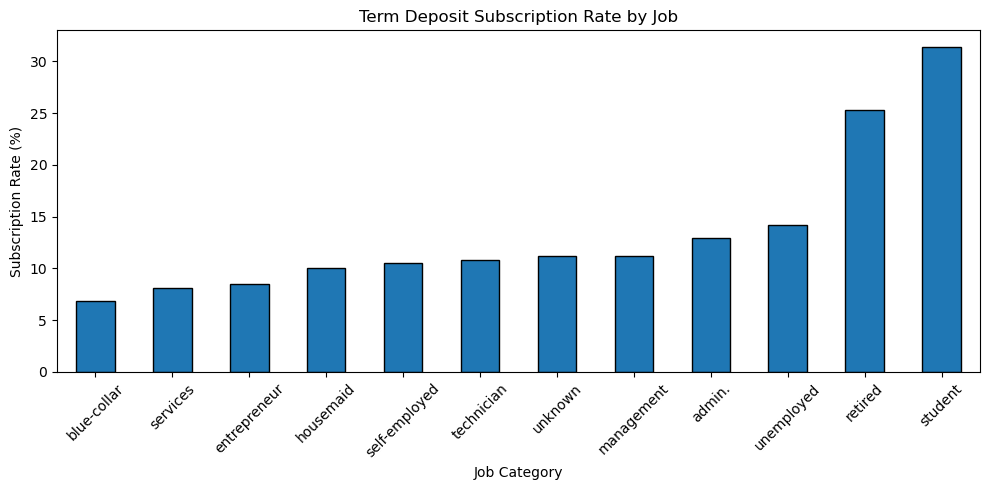

In [8]:
# Calculate subscription rate for each job category

subscription_rate = pd.crosstab(
    df["job"],
    df["y"],
    normalize="index"
) * 100

print(subscription_rate.round(2))

# Plot subscription rate for "yes"
subscription_rate["yes"].sort_values().plot(
    kind="bar",
    figsize=(10, 5),
    edgecolor="black"
)

plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Job Category")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

y         no  yes
month            
apr     2092  539
aug     5521  655
dec       93   89
jul     6521  648
jun     4759  559
mar      270  276
may    12881  886
nov     3684  416
oct      402  315
sep      314  256


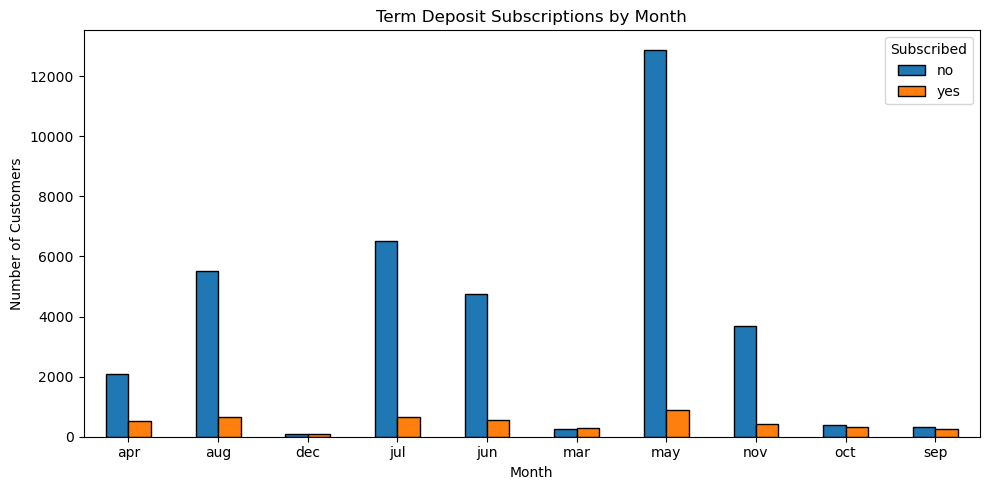

In [9]:
# Calculate monthly subscription counts
monthly_data = pd.crosstab(
    df["month"],
    df["y"]
)

print(monthly_data)

# Plot monthly subscriptions
monthly_data.plot(
    kind="bar",
    figsize=(10, 5),
    edgecolor="black"
)

plt.title("Term Deposit Subscriptions by Month")
plt.xlabel("Month")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Subscribed")
plt.tight_layout()
plt.show()

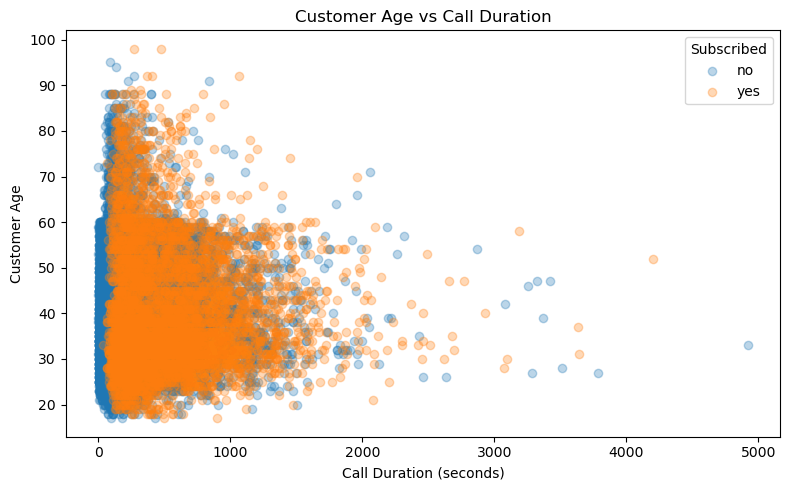

In [10]:
# Relationship between call duration and subscription

plt.figure(figsize=(8, 5))

for outcome in ["no", "yes"]:
    subset = df[df["y"] == outcome]

    plt.scatter(
        subset["duration"],
        subset["age"],
        label=outcome,
        alpha=0.3
    )

plt.title("Customer Age vs Call Duration")
plt.xlabel("Call Duration (seconds)")
plt.ylabel("Customer Age")
plt.legend(title="Subscribed")
plt.tight_layout()
plt.show()

y                       no   yes
education                       
basic.4y              3748   428
basic.6y              2103   188
basic.9y              5572   473
high.school           8481  1031
illiterate              14     4
professional.course   4645   595
university.degree    10495  1669
unknown               1479   251

Subscription rate by education (%):
y                       no    yes
education                        
basic.4y             89.75  10.25
basic.6y             91.79   8.21
basic.9y             92.18   7.82
high.school          89.16  10.84
illiterate           77.78  22.22
professional.course  88.65  11.35
university.degree    86.28  13.72
unknown              85.49  14.51


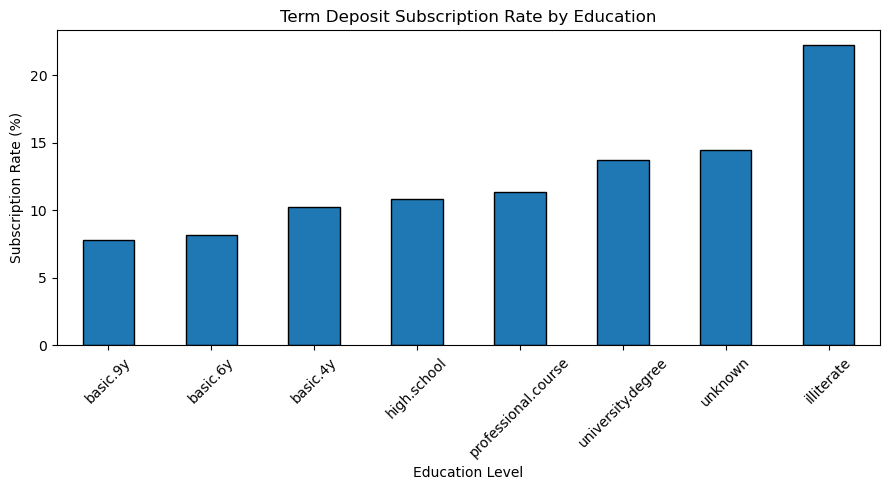

In [11]:
# Count subscription outcomes by education

education_data = pd.crosstab(
    df["education"],
    df["y"]
)

print(education_data)

# Calculate subscription percentage within each education category
education_rate = pd.crosstab(
    df["education"],
    df["y"],
    normalize="index"
) * 100

print("\nSubscription rate by education (%):")
print(education_rate.round(2))

# Plot subscription rates
education_rate["yes"].sort_values().plot(
    kind="bar",
    figsize=(9, 5),
    edgecolor="black"
)

plt.title("Term Deposit Subscription Rate by Education")
plt.xlabel("Education Level")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Subscription counts by contact method:
y             no   yes
contact               
cellular   22283  3852
telephone  14254   787

Subscription rate (%):
y             no    yes
contact                
cellular   85.26  14.74
telephone  94.77   5.23


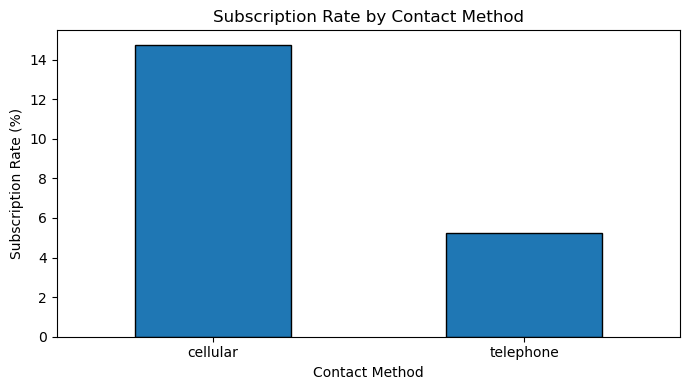

In [12]:
# Count subscription outcomes by contact method
contact_data = pd.crosstab(df["contact"], df["y"])

print("Subscription counts by contact method:")
print(contact_data)

# Calculate subscription rates
contact_rate = pd.crosstab(
    df["contact"],
    df["y"],
    normalize="index"
) * 100

print("\nSubscription rate (%):")
print(contact_rate.round(2))

# Plot subscription rates
contact_rate["yes"].plot(
    kind="bar",
    figsize=(7, 4),
    edgecolor="black"
)

plt.title("Subscription Rate by Contact Method")
plt.xlabel("Contact Method")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Subscription counts by previous outcome:
y               no   yes
poutcome                
failure       3647   605
nonexistent  32411  3140
success        479   894

Subscription rate (%):
y               no    yes
poutcome                 
failure      85.77  14.23
nonexistent  91.17   8.83
success      34.89  65.11


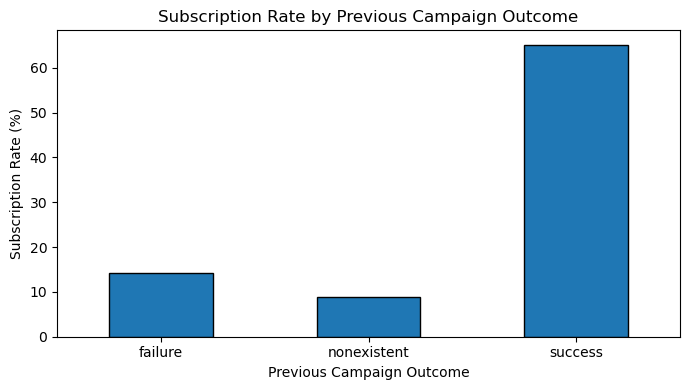

In [13]:
# Analyze subscription by previous campaign outcome

poutcome_data = pd.crosstab(
    df["poutcome"],
    df["y"]
)

print("Subscription counts by previous outcome:")
print(poutcome_data)

# Calculate subscription rates
poutcome_rate = pd.crosstab(
    df["poutcome"],
    df["y"],
    normalize="index"
) * 100

print("\nSubscription rate (%):")
print(poutcome_rate.round(2))

# Visualize subscription rates
poutcome_rate["yes"].plot(
    kind="bar",
    figsize=(7, 4),
    edgecolor="black"
)

plt.title("Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Subscription counts by marital status:
y            no   yes
marital              
divorced   4135   476
married   22390  2531
single     9944  1620
unknown      68    12

Subscription rate (%):
y            no    yes
marital               
divorced  89.68  10.32
married   89.84  10.16
single    85.99  14.01
unknown   85.00  15.00


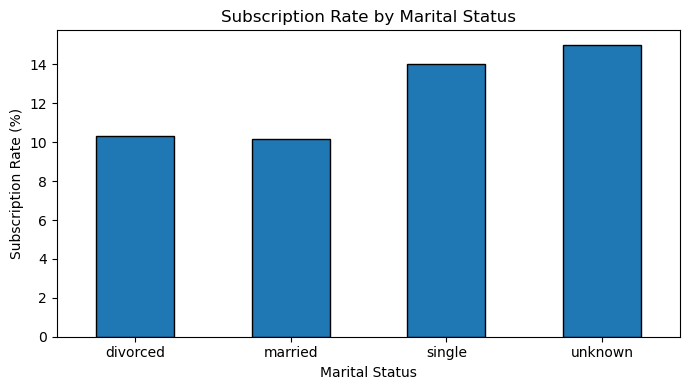

In [14]:
# Count subscription outcomes by marital status

marital_data = pd.crosstab(
    df["marital"],
    df["y"]
)

print("Subscription counts by marital status:")
print(marital_data)

# Calculate subscription percentage
marital_rate = pd.crosstab(
    df["marital"],
    df["y"],
    normalize="index"
) * 100

print("\nSubscription rate (%):")
print(marital_rate.round(2))

# Visualize subscription rates
marital_rate["yes"].plot(
    kind="bar",
    figsize=(7, 4),
    edgecolor="black"
)

plt.title("Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Subscription rate by age group (%):
y             no    yes
age_group              
18-25      79.04  20.96
26-35      88.28  11.72
36-45      91.49   8.51
46-55      91.31   8.69
56-65      84.78  15.22
66+        53.07  46.93


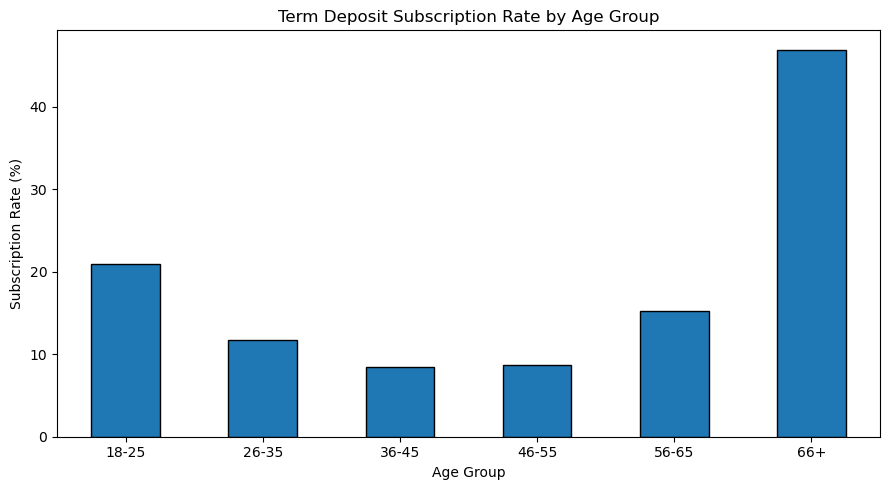

In [15]:
# Create age groups
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "66+"
    ],
    include_lowest=True
)

# Calculate subscription rate by age group
age_rate = pd.crosstab(
    df["age_group"],
    df["y"],
    normalize="index"
) * 100

print("Subscription rate by age group (%):")
print(age_rate.round(2))

# Plot subscription rates
age_rate["yes"].plot(
    kind="bar",
    figsize=(9, 5),
    edgecolor="black"
)

plt.title("Term Deposit Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

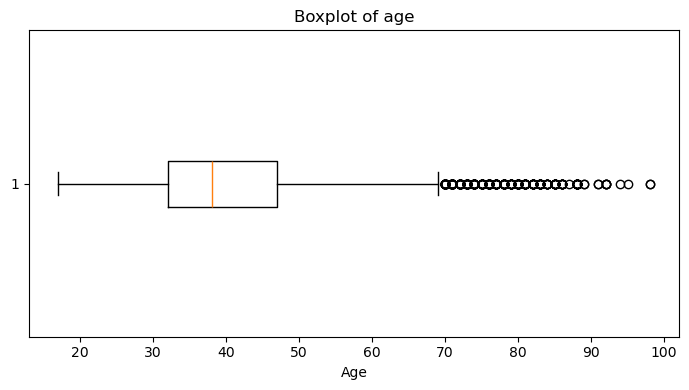

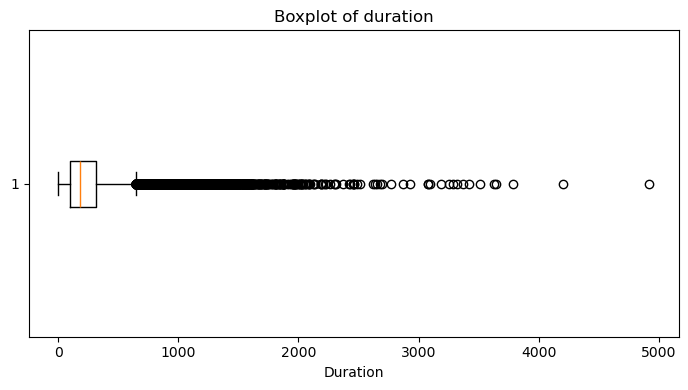

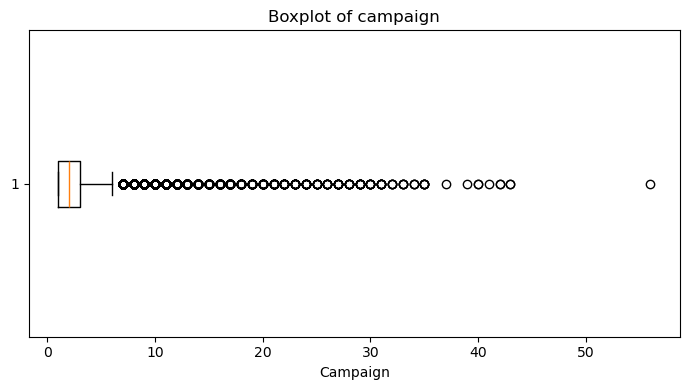

In [16]:
# Compare numerical distributions using boxplots

columns = ["age", "duration", "campaign"]

for col in columns:
    plt.figure(figsize=(7, 4))

    plt.boxplot(df[col].dropna(), vert=False)

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col.capitalize())

    plt.tight_layout()
    plt.show()

Campaign contact statistics:
count    41176.000000
mean         2.567879
std          2.770318
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         56.000000
Name: campaign, dtype: float64

Number of contacts by frequency:
campaign
1     17634
2     10568
3      5340
4      2650
5      1599
6       979
7       629
8       400
9       283
10      225
11      177
12      125
13       92
14       69
15       51
Name: count, dtype: int64


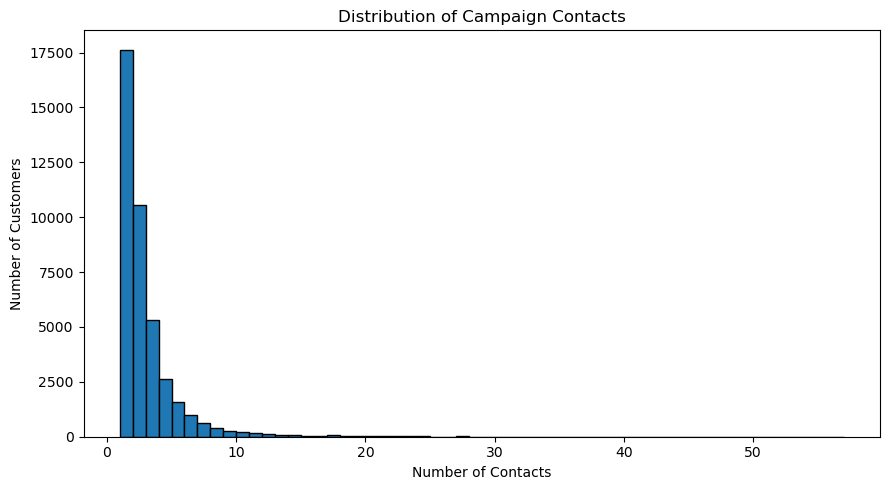

In [17]:
# Frequency distribution of campaign contacts

print("Campaign contact statistics:")
print(df["campaign"].describe())

print("\nNumber of contacts by frequency:")
print(df["campaign"].value_counts().sort_index().head(15))

# Plot distribution
plt.figure(figsize=(9, 5))

plt.hist(
    df["campaign"],
    bins=range(1, int(df["campaign"].max()) + 2),
    edgecolor="black"
)

plt.title("Distribution of Campaign Contacts")
plt.xlabel("Number of Contacts")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [18]:
# Final Exploratory Data Analysis Summary

print("========== EDA SUMMARY ==========")

print("\n1. Dataset Shape:")
print(df.shape)

print("\n2. Missing Values:")
print(df.isnull().sum().sum())

print("\n3. Duplicate Rows:")
print(df.duplicated().sum())

print("\n4. Average Customer Age:")
print(round(df["age"].mean(), 2))

print("\n5. Average Call Duration:")
print(round(df["duration"].mean(), 2), "seconds")

print("\n6. Average Campaign Contacts:")
print(round(df["campaign"].mean(), 2))

print("\n7. Subscription Counts:")
print(df["y"].value_counts())

print("\n8. Subscription Percentages:")
print((df["y"].value_counts(normalize=True) * 100).round(2))

print("\n9. Top 5 Job Categories:")
print(df["job"].value_counts().head(5))

print("\n========== END OF SUMMARY ==========")

========== EDA SUMMARY ==========

1. Dataset Shape:
(41176, 22)

2. Missing Values:
0

3. Duplicate Rows:
0

4. Average Customer Age:
40.02

5. Average Call Duration:
258.32 seconds

6. Average Campaign Contacts:
2.57

7. Subscription Counts:
y
no     36537
yes     4639
Name: count, dtype: int64

8. Subscription Percentages:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64

9. Top 5 Job Categories:
job
admin.         10419
blue-collar     9253
technician      6739
services        3967
management      2924
Name: count, dtype: int64

========== END OF SUMMARY ==========


In [19]:
from pathlib import Path

output_dir = Path("week2_outputs")
output_dir.mkdir(exist_ok=True)

print("Output folder ready:", output_dir.resolve())

Output folder ready: /Users/priyanshukumar/Documents/Internship/Bank Marketing Data Cleaning/week2_outputs


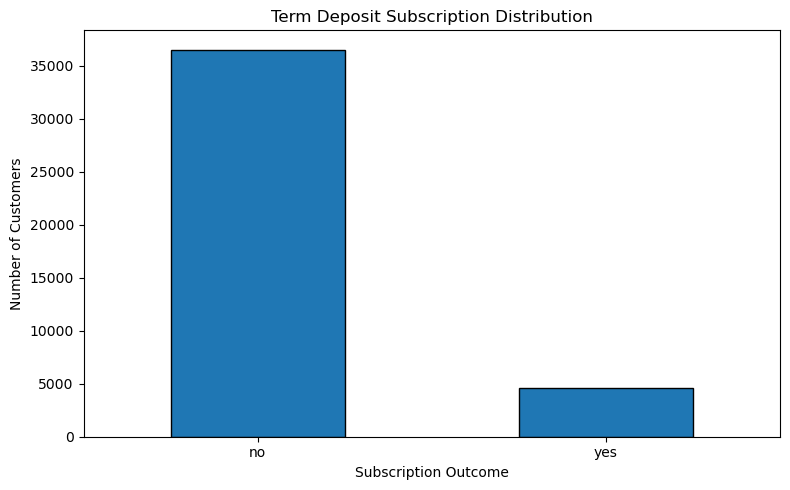

Chart saved successfully!


In [20]:
plt.figure(figsize=(8, 5))

df["y"].value_counts().reindex(["no", "yes"]).plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Term Deposit Subscription Distribution")
plt.xlabel("Subscription Outcome")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    output_dir / "subscription_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")

In [21]:
# Save the main EDA charts

# 1. Age distribution
plt.figure(figsize=(8, 5))
plt.hist(df["age"], bins=30, edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(output_dir / "age_distribution.png", dpi=300)
plt.close()

# 2. Call duration distribution
plt.figure(figsize=(8, 5))
plt.hist(df["duration"], bins=30, edgecolor="black")
plt.title("Call Duration Distribution")
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(output_dir / "duration_distribution.png", dpi=300)
plt.close()

# 3. Campaign contacts distribution
plt.figure(figsize=(8, 5))
plt.hist(df["campaign"], bins=30, edgecolor="black")
plt.title("Campaign Contact Distribution")
plt.xlabel("Number of Contacts")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(output_dir / "campaign_distribution.png", dpi=300)
plt.close()

print("Three charts saved successfully!")

Three charts saved successfully!


# Week 2: Data Exploration and Visualization
## 1. Project objectives
This week we aimed to analyze the cleaned Bank Marketing dataset, understand the numerical and categorical variables, find patterns, and visualize the relationships between the customer characteristics and the subscription of the term deposit.
## 2. Data Set Description
The analysis was performed on the cleaned dataset of Week 1, containing 41,176 records and 21 original columns. For data analysis and visualization, we used Python libraries, including Pandas, NumPy, and Matplotlib.
## 3. Statistics Analysis
Descriptive statistics were calculated for age, call duration, campaign contacts, and previous contacts. Mean, median, and standard deviation were used to describe central tendencies and variability of the data.
## 4. Data Visualization
The distributions of age, call duration, and campaign contacts were studied using histograms. Bar graphs were plotted to compare the outcome of subscription based on job category, education, marital status, contact, month, and previous campaign outcome. Boxplots were used to examine the distribution of numerical variables and to identify potential outliers.
## 5. Association and Correlation
A heatmap and correlation matrix were constructed for the selected numeric variables. Subscriber versus non-subscriber customer age, call duration, and campaign contacts were compared using grouped averages.
We also compared subscription percentage between customer categories and age groups. These comparisons show associations in the data observed, not causation.
## 6. Conclusion
The analysis gave me practical experience with exploratory data analysis, descriptive statistics, correlation analysis, and visualization. The charts and summary statistics help to highlight trends that can be used to drive additional investigation and future machine learning work.